In [2]:
pip install gwpy==3.0.14 pycbc==2.10.0 cryptography==43.0.0


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 190.0 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 194.0 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 300.5 kB/s eta 0:00:00a 0:00:01
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached pyyaml-6.0.3-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (2.4 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 kB 173.6 kB/s eta 0:00:00a 0:00:01
  Using cached markupsafe-3.0.3-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (2.7 kB)
  Using cached contourpy-1.3.3-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.7/118.7 kB 477.0 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.7/41.7 k

In [5]:
import gwpy
print("GWpy version: ", gwpy.__version__)
import pycbc
print("PyCBC version:", pycbc.__version__)

GWpy version:  3.0.14
PyCBC version: 2.10.0


In [2]:
from gwosc.datasets import event_gps
gps = event_gps('GW190412')
print(gps)

1239082262.1


In [3]:
start, end = segment= (int(gps)-5, int(gps)+5)
print(segment)

(1239082257, 1239082267)


In [9]:
from gwpy.timeseries import TimeSeries
ldata = TimeSeries.fetch_open_data('L1', *segment, verbose=True)
print(ldata)

Fetched 1 URLs from gwosc.org for [1239082257 .. 1239082267))
Reading data... [Done]
TimeSeries([-8.42597565e-19, -8.52437103e-19, -8.60738804e-19,
            ...,  1.38850270e-19,  1.37760541e-19,
             1.38094202e-19]
           unit: dimensionless,
           t0: 1239082257.0 s,
           dt: 0.000244140625 s,
           name: Strain,
           channel: None)


In [12]:
ldata.write('/home/ms/gwosc_data/my_strain_data.hdf5')

<Closed HDF5 dataset>

In [13]:
from gwpy.timeseries import TimeSeries

kdata = TimeSeries.read('/home/ms/gwosc_data/my_strain_data.hdf5')
print(kdata)

TimeSeries([-8.42597565e-19, -8.52437103e-19, -8.60738804e-19,
            ...,  1.38850270e-19,  1.37760541e-19,
             1.38094202e-19]
           unit: dimensionless,
           t0: 1239082257.0 s,
           dt: 0.000244140625 s,
           name: Strain,
           channel: None)


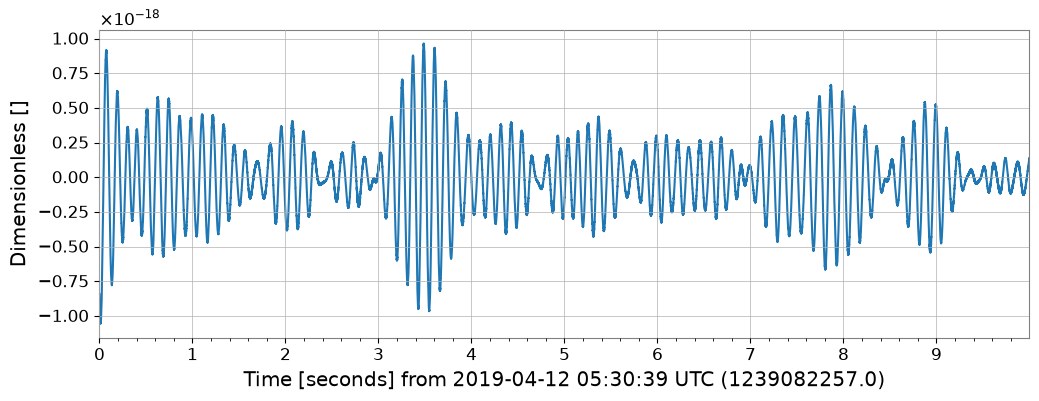

In [14]:
plot = kdata.plot()

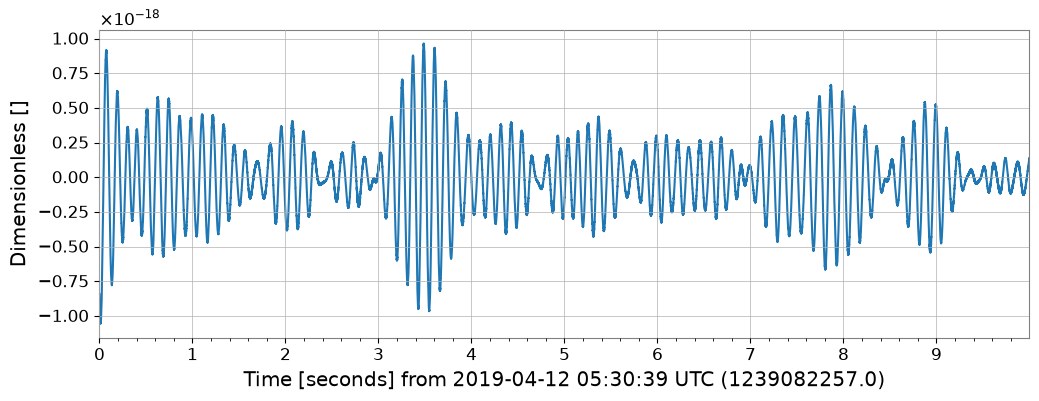

In [15]:

plot = ldata.plot()

In [16]:
from pycbc.frame.gwosc import read_strain_gwosc

ldata = read_strain_gwosc('L1', *segment)

In [22]:
from pycbc.frame import read_frame

local_data = read_frame('/home/ms/gwosc_data/my_strain_data.hdf5', 'L1:STRAIN')

TypeError: Invalid location name

In [23]:
from gwpy.timeseries import TimeSeries

# Read the local hdf5 file with GWpy
gwpy_data = TimeSeries.read('/home/ms/gwosc_data/my_strain_data.hdf5')

# Convert to PyCBC format
pycbc_data = gwpy_data.to_pycbc()

In [28]:
from pycbc.frame.gwosc import read_strain_gwosc

ldata = read_strain_gwosc('L1', *segment)

Text(0, 0.5, 'Strain (dimensionless)')

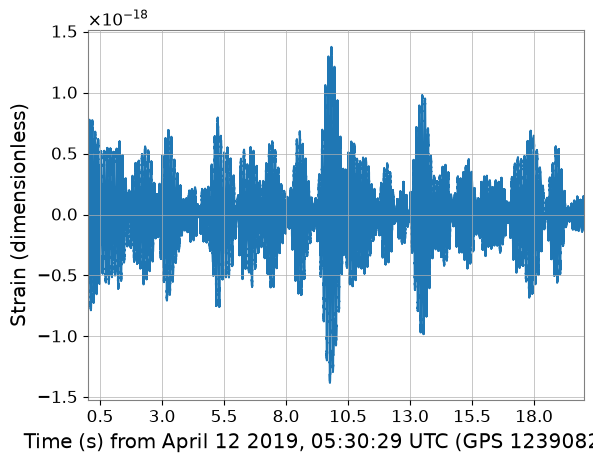

In [29]:
from lal.gpstime import gps_to_str

line = ldata.plot()
figure = line[0].figure
axis = figure.gca()
ticks = axis.get_xticks()
axis.set_xticks(ticks, labels = (ticks - start))
axis.set_xlim(start, stop)
axis.set_xlabel("Time (s) from {0} (GPS {1})". format(gps_to_str(start), start))
axis.set_ylabel("Strain (dimensionless)")

In [ ]:
from pycbc.frame.gwosc import read_strain_gwosc

vdata = read_strain_gwosc('H1', *segment)

In [ ]:
from lal.gpstime import gps_to_str

line = vdata.plot()
figure = line[0].figure
axis = figure.gca()
ticks = axis.get_xticks()
axis.set_xticks(ticks, labels=(ticks - start))
axis.set_xlim(start, stop)
axis.set_xlabel("Time (s) from {0} (GPS {1})".format(gps_to_str(start), start))
axis.set_ylabel("Strain (dimensionless)")